# 2025 Car Fuel Economy Analysis
Python/Jupyter port of the R script. Data is pulled directly from fueleconomy.gov (`25data.zip`).

Requires: `pandas`, `numpy`, `matplotlib`, `scipy`, `statsmodels`, `openpyxl` (Excel reader used by pandas).

In [1]:
# Uncomment if packages are missing
# %pip install pandas numpy matplotlib scipy statsmodels openpyxl

In [2]:
import io
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.nonparametric.smoothers_lowess import lowess

## Load data

In [3]:
URL = "https://www.fueleconomy.gov/feg/epadata/25data.zip"

req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
with urllib.request.urlopen(req) as resp:
    zf = zipfile.ZipFile(io.BytesIO(resp.read()))

print(zf.namelist())

xlsx_name = [n for n in zf.namelist() if n.lower().endswith(".xlsx")][0]
df = pd.read_excel(io.BytesIO(zf.read(xlsx_name)), sheet_name="FEguide")

print(df.shape)
print(list(df.columns[:10]))

['20250814 MY25 ICE,EV,PHEV For DOE R2public.xlsx']
(868, 162)
['Model Year', 'Mfr Name', 'Division', 'Carline', 'Verify Mfr Cd', 'Index (Model Type Index)', 'Eng Displ', '# Cyl', 'Transmission', 'City FE (Guide) - Conventional Fuel']


## Clean data and build variables

In [4]:
# Only 2025 model year
data = df[df["Model Year"] == 2025].copy()

# Numeric columns
data["Eng_Displ"] = pd.to_numeric(data["Eng Displ"], errors="coerce")
data["Comb_FE"] = pd.to_numeric(data["Comb FE (Guide) - Conventional Fuel"], errors="coerce")
data["City_FE"] = pd.to_numeric(data["City FE (Guide) - Conventional Fuel"], errors="coerce")
data["Hwy_FE"] = pd.to_numeric(data["Hwy FE (Guide) - Conventional Fuel"], errors="coerce")

# Categorical variables
data["is_turbocharged"] = np.where(
    data["Air Aspiration Method Desc"].str.contains("Turbo", na=False),
    "Turbocharged", "Naturally Aspirated")

data["fuel_type"] = np.where(
    data["Fuel Usage Desc - Conventional Fuel"].str.contains("Premium", na=False),
    "Premium", "Regular")

drive = data["Drive Desc"]
data["drive_type"] = np.select(
    [drive.str.contains("All Wheel", na=False),
     drive.str.contains("Front", na=False),
     drive.str.contains("Rear", na=False)],
    ["AWD", "FWD", "RWD"], default="Other")

# Drop rows missing key variables
data = data.dropna(subset=["Eng_Displ", "Comb_FE"])
print(data.shape)

(868, 169)


## Hypothesis 1: Turbocharged vs Naturally Aspirated

In [5]:
turbo_data = data[data["is_turbocharged"] == "Turbocharged"]
na_data = data[data["is_turbocharged"] == "Naturally Aspirated"]

for name, d in [("Turbocharged", turbo_data), ("Naturally Aspirated", na_data)]:
    print(f"{name}: n={len(d)}, mean MPG={d['Comb_FE'].mean():.3f}, "
          f"sd={d['Comb_FE'].std():.3f}, mean displ={d['Eng_Displ'].mean():.3f}")

Turbocharged: n=586, mean MPG=22.778, sd=4.636, mean displ=2.703
Naturally Aspirated: n=282, mean MPG=26.209, sd=9.914, mean displ=3.484


### Plot 1: Aspiration type

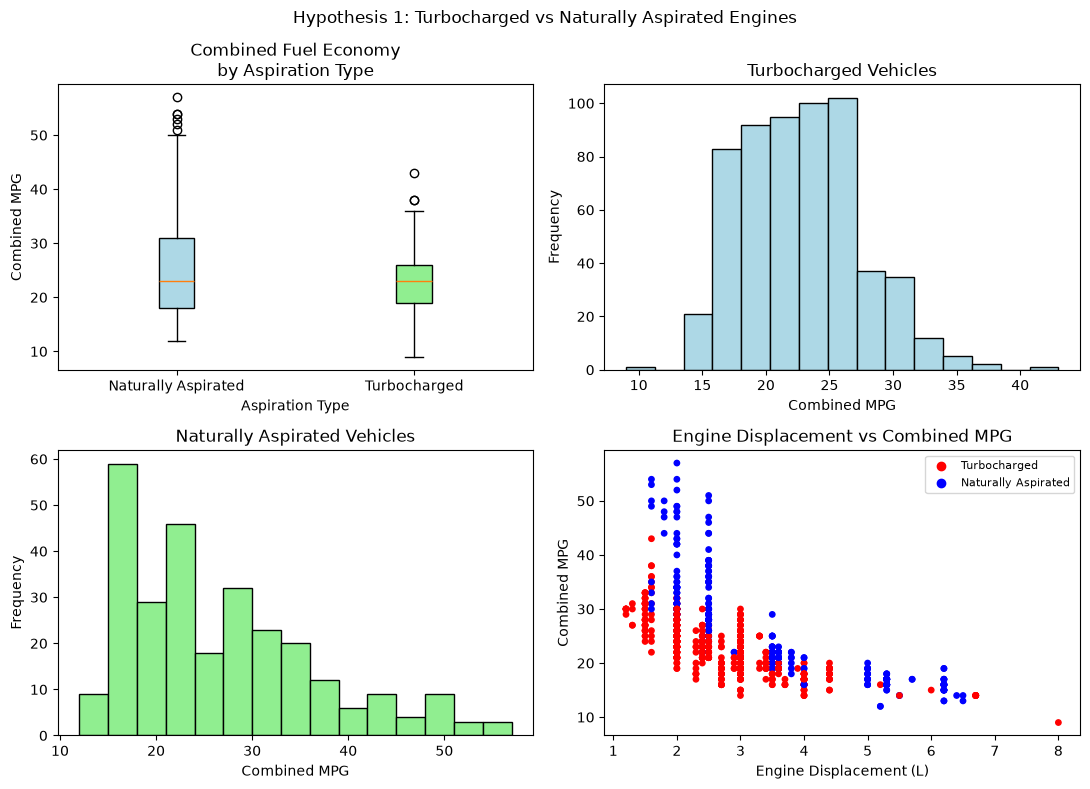

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

# Boxplot
bp = axes[0, 0].boxplot([na_data["Comb_FE"], turbo_data["Comb_FE"]],
                        tick_labels=["Naturally Aspirated", "Turbocharged"],
                        patch_artist=True)
for patch, c in zip(bp["boxes"], ["lightblue", "lightgreen"]):
    patch.set_facecolor(c)
axes[0, 0].set(title="Combined Fuel Economy\nby Aspiration Type",
               xlabel="Aspiration Type", ylabel="Combined MPG")

# Histograms
axes[0, 1].hist(turbo_data["Comb_FE"], bins=15, color="lightblue", edgecolor="black")
axes[0, 1].set(title="Turbocharged Vehicles", xlabel="Combined MPG", ylabel="Frequency")

axes[1, 0].hist(na_data["Comb_FE"], bins=15, color="lightgreen", edgecolor="black")
axes[1, 0].set(title="Naturally Aspirated Vehicles", xlabel="Combined MPG", ylabel="Frequency")

# Scatter
colors = np.where(data["is_turbocharged"] == "Turbocharged", "red", "blue")
axes[1, 1].scatter(data["Eng_Displ"], data["Comb_FE"], c=colors, s=15)
axes[1, 1].scatter([], [], c="red", label="Turbocharged")
axes[1, 1].scatter([], [], c="blue", label="Naturally Aspirated")
axes[1, 1].legend(loc="upper right", fontsize=8)
axes[1, 1].set(title="Engine Displacement vs Combined MPG",
               xlabel="Engine Displacement (L)", ylabel="Combined MPG")

fig.suptitle("Hypothesis 1: Turbocharged vs Naturally Aspirated Engines")
plt.tight_layout()
plt.show()

In [7]:
# Welch t-test (same as R's default t.test)
def welch(df, value, group):
    levels = sorted(df[group].unique())
    a = df.loc[df[group] == levels[0], value]
    b = df.loc[df[group] == levels[1], value]
    res = stats.ttest_ind(a, b, equal_var=False)
    ci = res.confidence_interval()
    print(f"{value} by {group}: {levels[0]} (mean={a.mean():.3f}) vs {levels[1]} (mean={b.mean():.3f})")
    print(f"  t = {res.statistic:.4f}, df = {res.df:.2f}, p = {res.pvalue:.4g}")
    print(f"  95% CI of difference: [{ci.low:.3f}, {ci.high:.3f}]\n")
    return res

t_test_result = welch(data, "Comb_FE", "is_turbocharged")

# Linear model controlling for displacement
lm_model1 = smf.ols("Comb_FE ~ C(is_turbocharged) + Eng_Displ", data=data).fit()
print(lm_model1.summary())

Comb_FE by is_turbocharged: Naturally Aspirated (mean=26.209) vs Turbocharged (mean=22.778)
  t = 5.5283, df = 341.45, p = 6.434e-08
  95% CI of difference: [2.210, 4.652]

                            OLS Regression Results                            
Dep. Variable:                Comb_FE   R-squared:                       0.598
Model:                            OLS   Adj. R-squared:                  0.597
Method:                 Least Squares   F-statistic:                     643.6
Date:                Sun, 11 Oct 2026   Prob (F-statistic):          6.16e-172
Time:                        16:46:39   Log-Likelihood:                -2524.1
No. Observations:                 868   AIC:                             5054.
Df Residuals:                     865   BIC:                             5068.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                                     

## Hypothesis 2: Premium vs Regular fuel

In [8]:
premium_data = data[data["fuel_type"] == "Premium"]
regular_data = data[data["fuel_type"] == "Regular"]

for name, d in [("Premium", premium_data), ("Regular", regular_data)]:
    print(f"{name}: n={len(d)}, Comb={d['Comb_FE'].mean():.3f}, "
          f"City={d['City_FE'].mean():.3f}, Hwy={d['Hwy_FE'].mean():.3f}")

Premium: n=433, Comb=21.785, City=19.319, Hwy=25.965
Regular: n=435, Comb=25.991, City=24.179, Hwy=28.885


### Plot 2: Fuel type

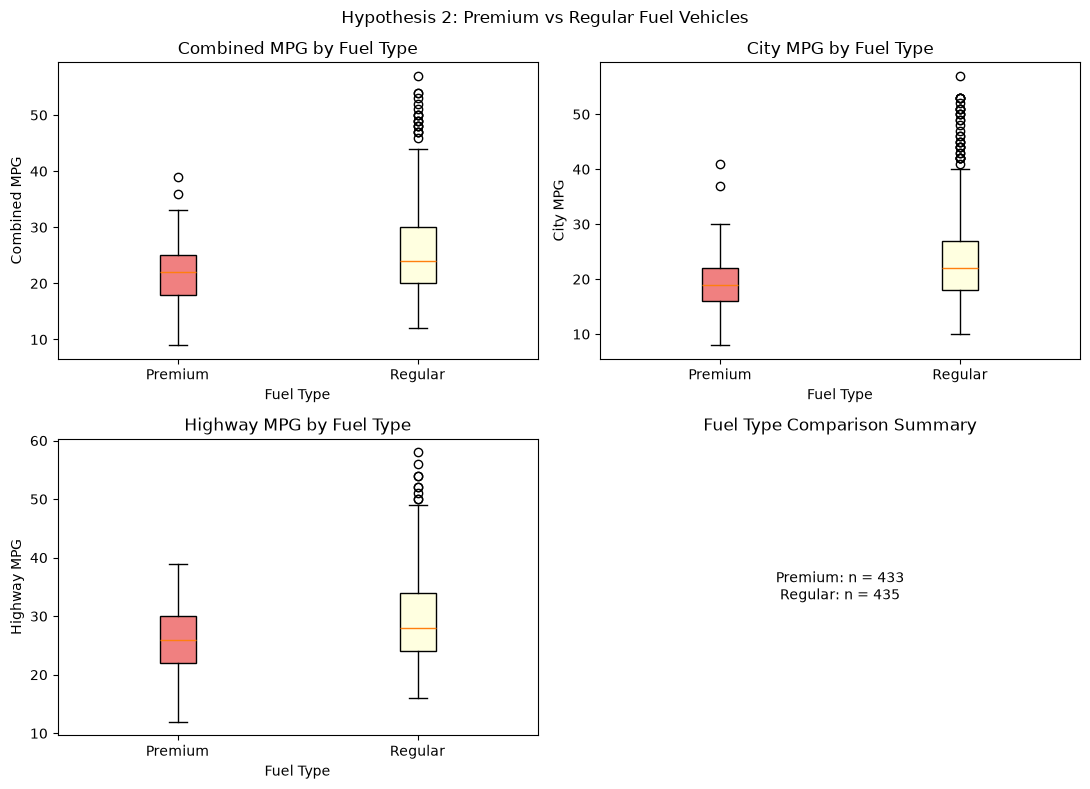

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

def fuel_box(ax, col, title, ylabel):
    bp = ax.boxplot([premium_data[col].dropna(), regular_data[col].dropna()],
                    tick_labels=["Premium", "Regular"], patch_artist=True)
    for patch, c in zip(bp["boxes"], ["lightcoral", "lightyellow"]):
        patch.set_facecolor(c)
    ax.set(title=title, xlabel="Fuel Type", ylabel=ylabel)

fuel_box(axes[0, 0], "Comb_FE", "Combined MPG by Fuel Type", "Combined MPG")
fuel_box(axes[0, 1], "City_FE", "City MPG by Fuel Type", "City MPG")
fuel_box(axes[1, 0], "Hwy_FE", "Highway MPG by Fuel Type", "Highway MPG")

# Info panel
axes[1, 1].axis("off")
axes[1, 1].set_title("Fuel Type Comparison Summary")
axes[1, 1].text(0.5, 0.5, f"Premium: n = {len(premium_data)}\nRegular: n = {len(regular_data)}",
                ha="center", va="center")

fig.suptitle("Hypothesis 2: Premium vs Regular Fuel Vehicles")
plt.tight_layout()
plt.show()

In [10]:
t_comb = welch(data, "Comb_FE", "fuel_type")
t_city = welch(data, "City_FE", "fuel_type")
t_hwy = welch(data, "Hwy_FE", "fuel_type")

Comb_FE by fuel_type: Premium (mean=21.785) vs Regular (mean=25.991)
  t = -9.2908, df = 693.41, p = 1.943e-19
  95% CI of difference: [-5.094, -3.317]

City_FE by fuel_type: Premium (mean=19.319) vs Regular (mean=24.179)
  t = -10.2189, df = 635.83, p = 8.429e-23
  95% CI of difference: [-5.795, -3.927]

Hwy_FE by fuel_type: Premium (mean=25.965) vs Regular (mean=28.885)
  t = -6.5804, df = 773.60, p = 8.644e-11
  95% CI of difference: [-3.791, -2.049]



## Correlation analysis

In [11]:
cor_vars = data[["Comb_FE", "Eng_Displ", "City_FE", "Hwy_FE"]]
cor_matrix = cor_vars.corr()
cor_matrix

,Comb_FE,Eng_Displ,City_FE,Hwy_FE
Comb_FE,1.000000,-0.629437,0.986073,0.959177
Eng_Displ,-0.629437,1.000000,-0.587986,-0.645510
City_FE,0.986073,-0.587986,1.000000,0.905128
Hwy_FE,0.959177,-0.645510,0.905128,1.000000


### Plot 3: Scatterplot matrix

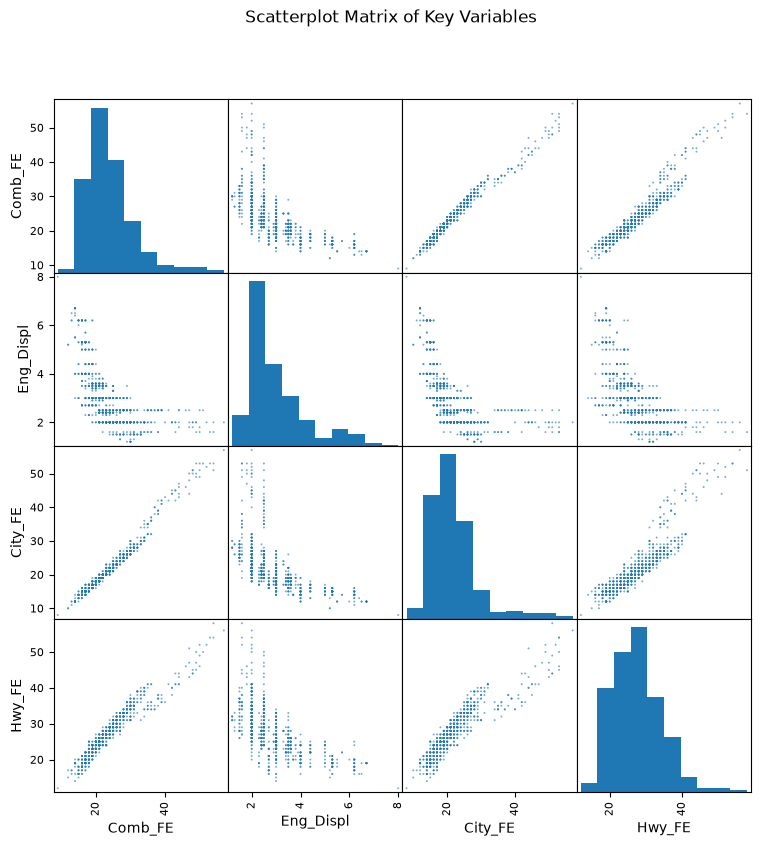

In [12]:
axes = pd.plotting.scatter_matrix(cor_vars, figsize=(9, 9), s=8, alpha=0.6, diagonal="hist")
plt.suptitle("Scatterplot Matrix of Key Variables")
plt.show()

## Two-way ANOVA: fuel type × aspiration type

In [13]:
anova_model = smf.ols("Comb_FE ~ C(fuel_type) * C(is_turbocharged)", data=data).fit()
anova_lm(anova_model, typ=1)  # sequential SS, matches R's aov()

,df,sum_sq,mean_sq,F,PR(>F)
C(fuel_type),1.0,3838.047092,3838.047092,92.735516,6.421179e-21
C(is_turbocharged),1.0,698.490023,698.490023,16.877029,4.367368e-05
C(fuel_type):C(is_turbocharged),1.0,2138.109358,2138.109358,51.661345,1.426571e-12
Residual,864.0,35758.389242,41.387025,NaN,NaN


## Displacement category analysis

In [14]:
data["displ_category"] = pd.cut(
    data["Eng_Displ"],
    bins=[0, 2, 3, 4, data["Eng_Displ"].max()],
    labels=["Small (<2L)", "Medium (2-3L)", "Large (3-4L)", "Very Large (>4L)"])

displ_summary = (data.groupby(["displ_category", "is_turbocharged"], observed=True)["Comb_FE"]
                     .agg(mean="mean", count="count")
                     .reset_index())
displ_summary

,displ_category,is_turbocharged,mean,count
0,Small (<2L),Naturally Aspirated,37.629032,62
1,Small (<2L),Turbocharged,26.735849,212
2,Medium (2-3L),Naturally Aspirated,31.153846,78
3,Medium (2-3L),Turbocharged,21.714286,259
4,Large (3-4L),Naturally Aspirated,21.238095,63
5,Large (3-4L),Turbocharged,18.380952,84
6,Very Large (>4L),Naturally Aspirated,16.329114,79
7,Very Large (>4L),Turbocharged,16.516129,31


### Plot 4: MPG by displacement and aspiration type

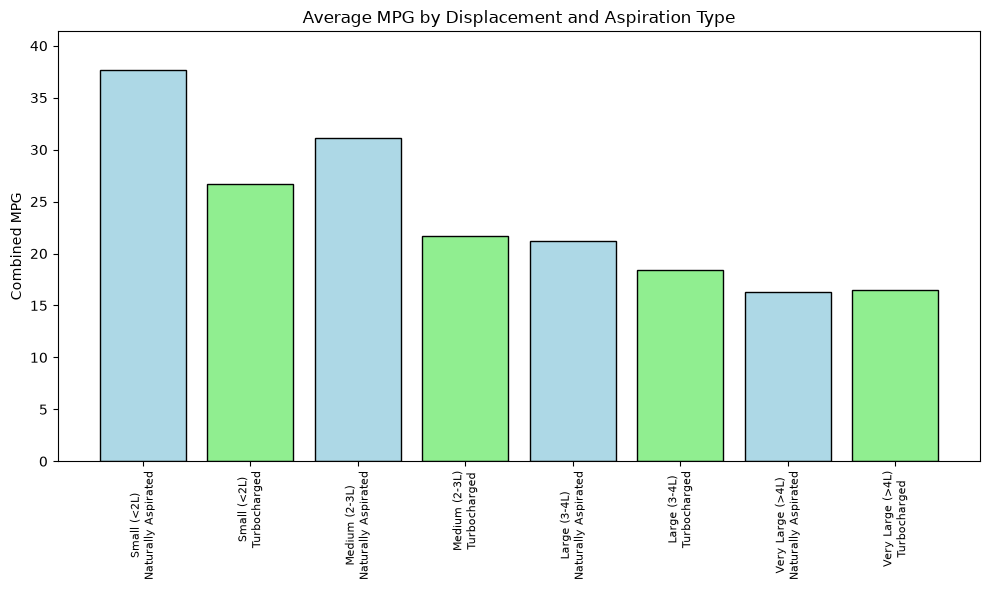

In [15]:
labels = displ_summary["displ_category"].astype(str) + "\n" + displ_summary["is_turbocharged"]
bar_colors = ["lightblue", "lightgreen"] * (len(displ_summary) // 2 + 1)

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(range(len(displ_summary)), displ_summary["mean"],
       color=bar_colors[:len(displ_summary)], edgecolor="black")
ax.set_xticks(range(len(displ_summary)))
ax.set_xticklabels(labels, rotation=90, fontsize=8)
ax.set(title="Average MPG by Displacement and Aspiration Type", ylabel="Combined MPG",
       ylim=(0, displ_summary["mean"].max() * 1.1))
plt.tight_layout()
plt.show()

## Final comprehensive model

In [16]:
final_model = smf.ols("Comb_FE ~ C(fuel_type) + C(is_turbocharged) + Eng_Displ + C(drive_type)",
                      data=data).fit()
print(final_model.summary())

                            OLS Regression Results                            
Dep. Variable:                Comb_FE   R-squared:                       0.634
Model:                            OLS   Adj. R-squared:                  0.631
Method:                 Least Squares   F-statistic:                     248.2
Date:                Sun, 11 Oct 2026   Prob (F-statistic):          6.90e-184
Time:                        16:46:41   Log-Likelihood:                -2483.9
No. Observations:                 868   AIC:                             4982.
Df Residuals:                     861   BIC:                             5015.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
Inte

### Plot 5: Model diagnostics

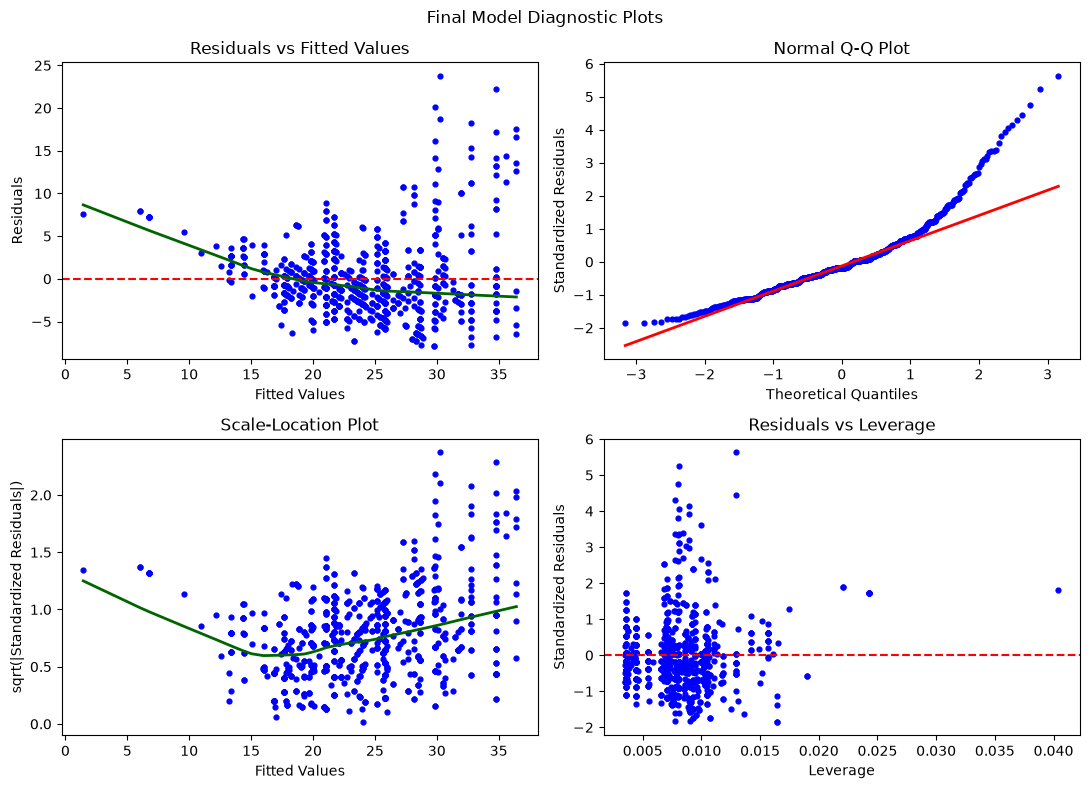

In [17]:
resid = final_model.resid
fitted = final_model.fittedvalues
infl = final_model.get_influence()
std_resid = infl.resid_studentized_internal   # equivalent to R's rstandard()
leverage = infl.hat_matrix_diag

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

# Residuals vs Fitted
ax = axes[0, 0]
ax.scatter(fitted, resid, s=12, color="blue")
ax.axhline(0, color="red", ls="--")
sm_line = lowess(resid, fitted)
ax.plot(sm_line[:, 0], sm_line[:, 1], color="darkgreen", lw=2)
ax.set(title="Residuals vs Fitted Values", xlabel="Fitted Values", ylabel="Residuals")

# Normal Q-Q
ax = axes[0, 1]
(osm, osr), _ = stats.probplot(std_resid, dist="norm")
ax.scatter(osm, osr, s=12, color="blue")
x1, x2 = stats.norm.ppf([0.25, 0.75])
y1, y2 = np.quantile(std_resid, [0.25, 0.75])
slope = (y2 - y1) / (x2 - x1)
ax.plot(osm, y1 + slope * (osm - x1), color="red", lw=2)   # same as R's qqline()
ax.set(title="Normal Q-Q Plot", xlabel="Theoretical Quantiles", ylabel="Standardized Residuals")

# Scale-Location
ax = axes[1, 0]
sqrt_abs = np.sqrt(np.abs(std_resid))
ax.scatter(fitted, sqrt_abs, s=12, color="blue")
sm_line = lowess(sqrt_abs, fitted)
ax.plot(sm_line[:, 0], sm_line[:, 1], color="darkgreen", lw=2)
ax.set(title="Scale-Location Plot", xlabel="Fitted Values",
       ylabel="sqrt(|Standardized Residuals|)")

# Residuals vs Leverage
ax = axes[1, 1]
ax.scatter(leverage, std_resid, s=12, color="blue")
ax.axhline(0, color="red", ls="--")
ax.set(title="Residuals vs Leverage", xlabel="Leverage", ylabel="Standardized Residuals")

fig.suptitle("Final Model Diagnostic Plots")
plt.tight_layout()
plt.show()

## Key comparative metrics

In [18]:
mean_turbo = turbo_data["Comb_FE"].mean()
mean_na = na_data["Comb_FE"].mean()
mean_premium = premium_data["Comb_FE"].mean()
mean_regular = regular_data["Comb_FE"].mean()

print(f"Mean MPG - Turbocharged:        {mean_turbo:.3f}")
print(f"Mean MPG - Naturally Aspirated: {mean_na:.3f}")
print(f"Mean MPG - Premium:             {mean_premium:.3f}")
print(f"Mean MPG - Regular:             {mean_regular:.3f}")
print(f"Turbo - NA difference:          {mean_turbo - mean_na:.3f}")
print(f"Premium - Regular difference:   {mean_premium - mean_regular:.3f}")
print(f"p-value (turbo vs NA):          {t_test_result.pvalue:.4g}")
print(f"p-value (premium vs regular):   {t_comb.pvalue:.4g}")
print(f"Correlation (displacement, MPG): {data['Eng_Displ'].corr(data['Comb_FE']):.3f}")

Mean MPG - Turbocharged:        22.778
Mean MPG - Naturally Aspirated: 26.209
Mean MPG - Premium:             21.785
Mean MPG - Regular:             25.991
Turbo - NA difference:          -3.431
Premium - Regular difference:   -4.206
p-value (turbo vs NA):          6.434e-08
p-value (premium vs regular):   1.943e-19
Correlation (displacement, MPG): -0.629
